<a href="https://colab.research.google.com/github/rsjayasri20/CODEORBIT_EDA/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== DATASET SHAPE ==========
(395, 33)

========== FIRST 5 ROWS ==========
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

=====

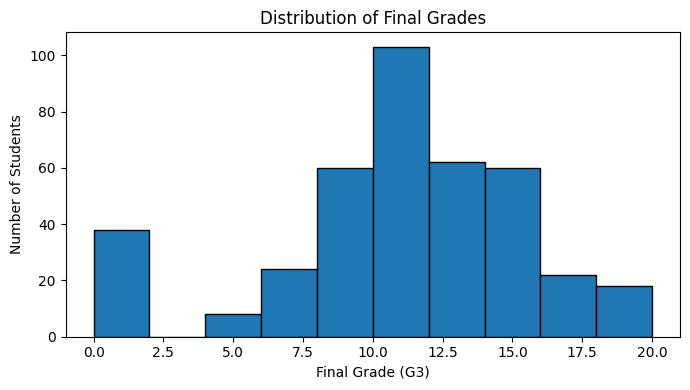

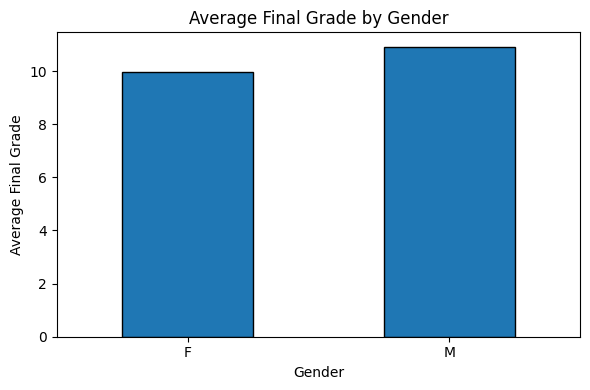

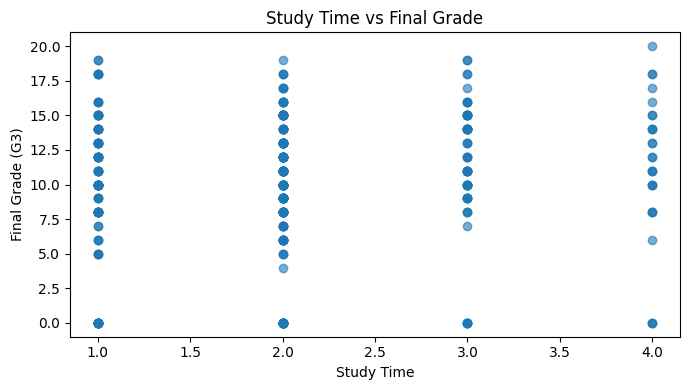

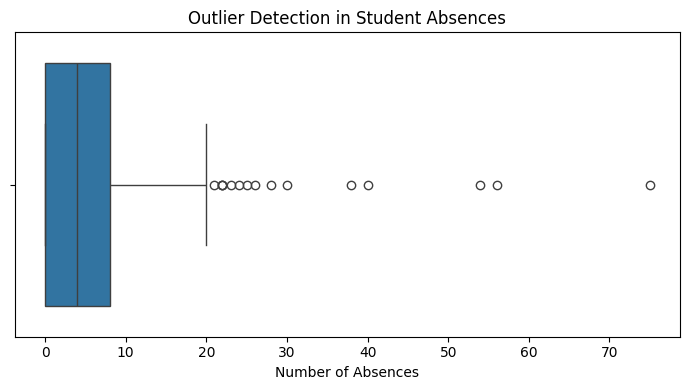


Potential outliers in absences: 15


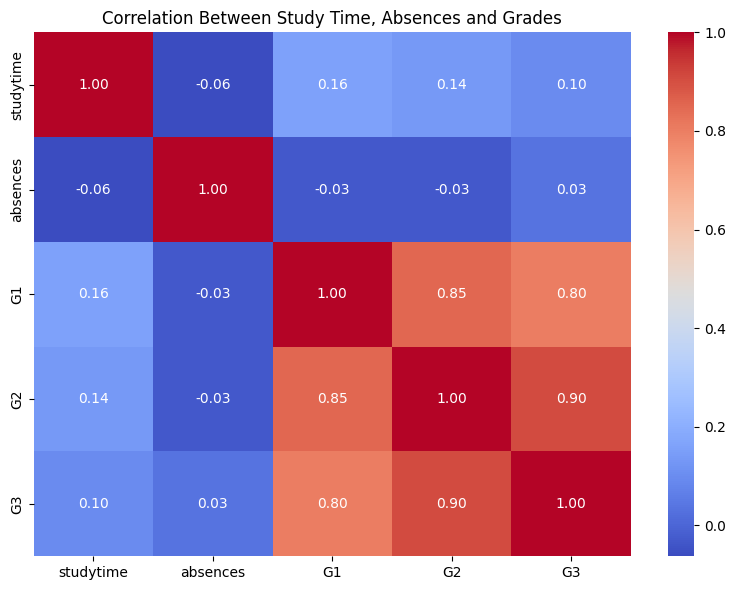


========== KEY FINDINGS ==========
Total students: 395
Average final grade: 10.42
Highest final grade: 20
Lowest final grade: 0
Average study time: 2.04
Average absences: 5.71

Average final grade by gender:
sex
F     9.97
M    10.91
Name: G3, dtype: float64

Correlation between study time and final grade: 0.1

Correlation between absences and final grade: 0.03


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==================================================
# 1. LOAD DATASET
# ==================================================

df = pd.read_csv('student-mat.csv', sep=';')

print("========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe())


# ==================================================
# 2. CHECK MISSING VALUES AND DUPLICATES
# ==================================================

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


# ==================================================
# 3. HISTOGRAM - DISTRIBUTION OF FINAL GRADES
# ==================================================

plt.figure(figsize=(7, 4))
plt.hist(df['G3'], bins=10, edgecolor='black')
plt.title('Distribution of Final Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()


# ==================================================
# 4. BAR CHART - AVERAGE GRADE BY GENDER
# ==================================================

avg_grade = df.groupby('sex')['G3'].mean()

plt.figure(figsize=(6, 4))
avg_grade.plot(kind='bar', edgecolor='black')
plt.title('Average Final Grade by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Final Grade')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==================================================
# 5. SCATTER PLOT - STUDY TIME VS FINAL GRADE
# ==================================================

plt.figure(figsize=(7, 4))
plt.scatter(df['studytime'], df['G3'], alpha=0.6)
plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Final Grade (G3)')
plt.tight_layout()
plt.show()


# ==================================================
# 6. BOX PLOT - OUTLIER DETECTION
# ==================================================

plt.figure(figsize=(7, 4))
sns.boxplot(x=df['absences'])
plt.title('Outlier Detection in Student Absences')
plt.xlabel('Number of Absences')
plt.tight_layout()
plt.show()

Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df['absences'] < Q1 - 1.5 * IQR) |
    (df['absences'] > Q3 + 1.5 * IQR)
]

print("\nPotential outliers in absences:", len(outliers))


# ==================================================
# 7. CORRELATION HEATMAP
# ==================================================

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[['studytime', 'absences', 'G1', 'G2', 'G3']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Between Study Time, Absences and Grades')
plt.tight_layout()
plt.show()


# ==================================================
# 8. KEY FINDINGS
# ==================================================

print("\n========== KEY FINDINGS ==========")

print("Total students:", len(df))
print("Average final grade:", round(df['G3'].mean(), 2))
print("Highest final grade:", df['G3'].max())
print("Lowest final grade:", df['G3'].min())
print("Average study time:", round(df['studytime'].mean(), 2))
print("Average absences:", round(df['absences'].mean(), 2))

print("\nAverage final grade by gender:")
print(avg_grade.round(2))

print("\nCorrelation between study time and final grade:",
      round(df['studytime'].corr(df['G3']), 2))

print("\nCorrelation between absences and final grade:",
      round(df['absences'].corr(df['G3']), 2))
